# 1. Load Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def load_data(data_path : str):
    df = pd.read_csv(f"{data_path}")

    return df

def save_data(df: pd.DataFrame, data_path : str):

    return df.to_csv(f"{data_path}", index = False)

DATA_DIR = "data/"

application_test = load_data(DATA_DIR + "application_test.csv")
application_train = load_data(DATA_DIR + "application_train.csv")

In [2]:
train = application_train.copy()
test = application_test.copy()

df = pd.concat([train,test],axis = 0, ignore_index = True)
df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1.0,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0.0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0.0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0.0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0.0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


# 2. Understand The Data (Data Type, Data Info, Missing Values and Duplicates)

## 2.1 Overall

### Data Type

In [3]:
print("Data Type:")
display(df.shape)

Data Type:


(356255, 122)

### Data Info

In [4]:
print("Data Type:")
display(df.info)

Data Type:


<bound method DataFrame.info of         SK_ID_CURR  TARGET NAME_CONTRACT_TYPE CODE_GENDER FLAG_OWN_CAR  \
0           100002     1.0         Cash loans           M            N   
1           100003     0.0         Cash loans           F            N   
2           100004     0.0    Revolving loans           M            Y   
3           100006     0.0         Cash loans           F            N   
4           100007     0.0         Cash loans           M            N   
...            ...     ...                ...         ...          ...   
356250      456221     NaN         Cash loans           F            N   
356251      456222     NaN         Cash loans           F            N   
356252      456223     NaN         Cash loans           F            Y   
356253      456224     NaN         Cash loans           M            N   
356254      456250     NaN         Cash loans           F            Y   

       FLAG_OWN_REALTY  CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  \
0        

### Missing Values

In [5]:
print("Missing Value: ")
missing_value_df =  df.isnull().sum().to_frame(name = 'Missing Count')
display(missing_value_df[missing_value_df['Missing Count'] > 0].sort_values(by = 'Missing Count', ascending = False))

Missing Value: 


,Missing Count
COMMONAREA_MODE,248360
COMMONAREA_MEDI,248360
COMMONAREA_AVG,248360
NONLIVINGAPARTMENTS_AVG,246861
NONLIVINGAPARTMENTS_MODE,246861
...,...
EXT_SOURCE_2,668
AMT_GOODS_PRICE,278
AMT_ANNUITY,36
CNT_FAM_MEMBERS,2


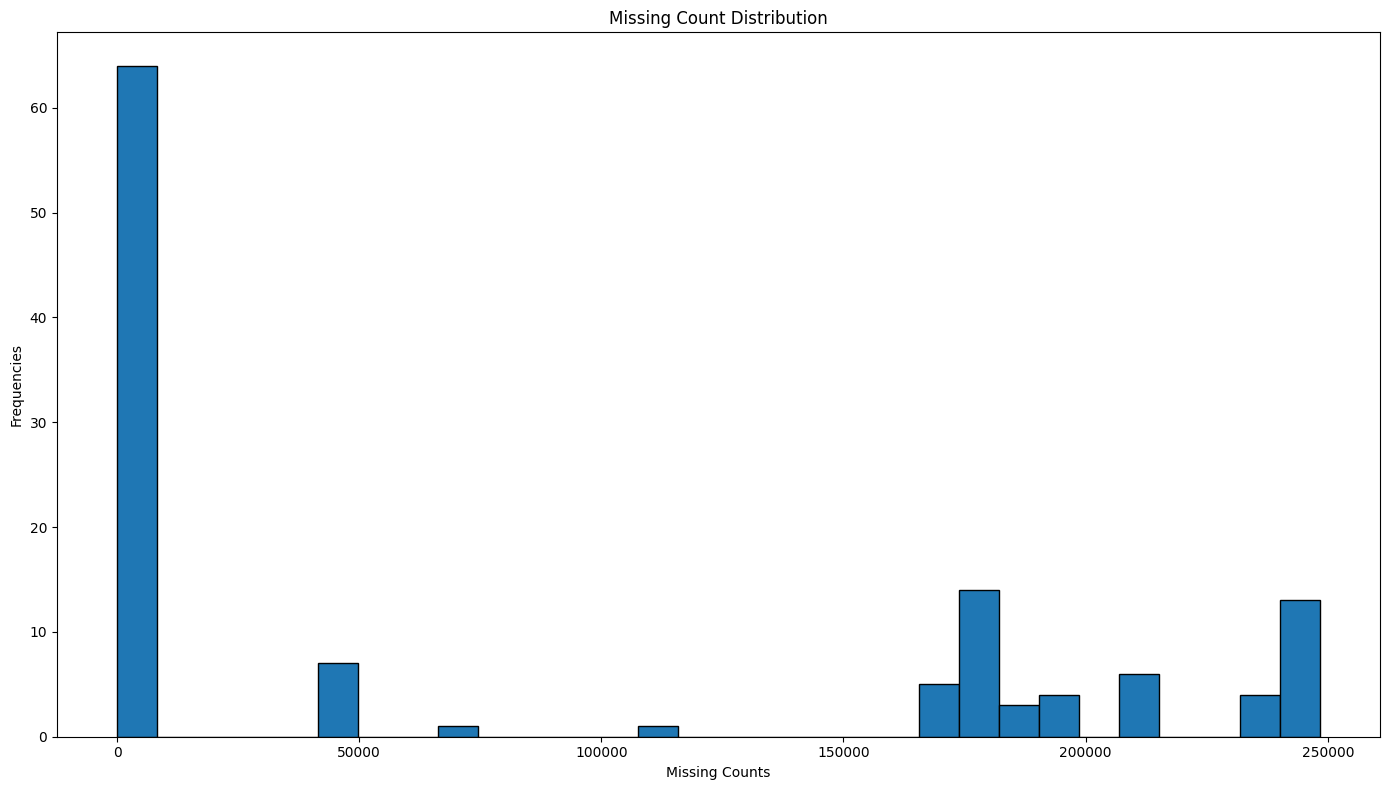

In [6]:
plt.figure(figsize = (14,8))
plt.hist(missing_value_df, bins = 30, edgecolor = 'black')
plt.xlabel('Missing Counts')
plt.ylabel('Frequencies')
plt.title("Missing Count Distribution")
plt.tight_layout()
plt.show()

### Statistic Summary

In [7]:
print("Statistic Summary: ")
display(df.describe())

Statistic Summary: 


,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,356255.000000,307511.000000,356255.000000,3.562550e+05,3.562550e+05,356219.000000,3.559770e+05,356255.000000,356255.000000,356255.000000,...,356255.000000,356255.000000,356255.000000,356255.000000,308687.000000,308687.000000,308687.000000,308687.000000,308687.000000,308687.000000
mean,278128.000000,0.080729,0.414316,1.701161e+05,5.877674e+05,27425.560657,5.280200e+05,0.020917,-16041.248841,64317.231413,...,0.007231,0.000514,0.000438,0.000289,0.005808,0.006281,0.029995,0.231697,0.304399,1.911564
std,102842.104413,0.272419,0.720378,2.235068e+05,3.986237e+05,14732.808190,3.660650e+05,0.013915,4358.803980,141705.532576,...,0.084726,0.022659,0.020921,0.017001,0.079736,0.104250,0.191374,0.855949,0.786915,1.865338
min,100001.000000,0.000000,0.000000,2.565000e+04,4.500000e+04,1615.500000,4.050000e+04,0.000253,-25229.000000,-17912.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,189064.500000,0.000000,0.000000,1.125000e+05,2.700000e+05,16731.000000,2.340000e+05,0.010006,-19676.000000,-2781.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,278128.000000,0.000000,0.000000,1.530000e+05,5.002110e+05,25078.500000,4.500000e+05,0.018850,-15755.000000,-1224.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
75%,367191.500000,0.000000,1.000000,2.025000e+05,7.975575e+05,34960.500000,6.750000e+05,0.028663,-12425.000000,-290.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000
max,456255.000000,1.000000,20.000000,1.170000e+08,4.050000e+06,258025.500000,4.050000e+06,0.072508,-7338.000000,365243.000000,...,1.000000,1.000000,1.000000,1.000000,4.000000,9.000000,8.000000,27.000000,261.000000,25.000000


## 2.2 Columns Identification

In [8]:
# Target
target = 'TARGET'

# Numeric and Categorical Columns
numeric_cols = list(df.drop(columns = ['SK_ID_CURR','TARGET']).select_dtypes(include = ['int64','float64']))
categorical_cols = list(df.select_dtypes(include = ['object']))

# Display
print(f"Numeric Columns: {numeric_cols}")
print(f"Categorical Columns: {categorical_cols}")
print(f"Target Column: {target}")

Numeric Columns: ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'ELEVATORS_AVG', 'ENTRANCES_AVG', 'FLOORSMAX_AVG', 'FLOORSMIN_AVG', 'LANDAREA_AVG', 'LIVINGAPARTMENTS_AVG', 'LIVINGAREA_AVG', 'NONLIVINGAPARTMENTS_AVG', 'NONLIVINGAREA_AVG', 'APARTMENTS_MODE', 'BASEMENTAREA_MODE', 'YEARS_BEGINEXPLUATATION_MODE', 'YEARS_BUILD

C:\Users\Admin\AppData\Local\Temp\ipykernel_7488\3376446784.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = list(df.select_dtypes(include = ['object']))


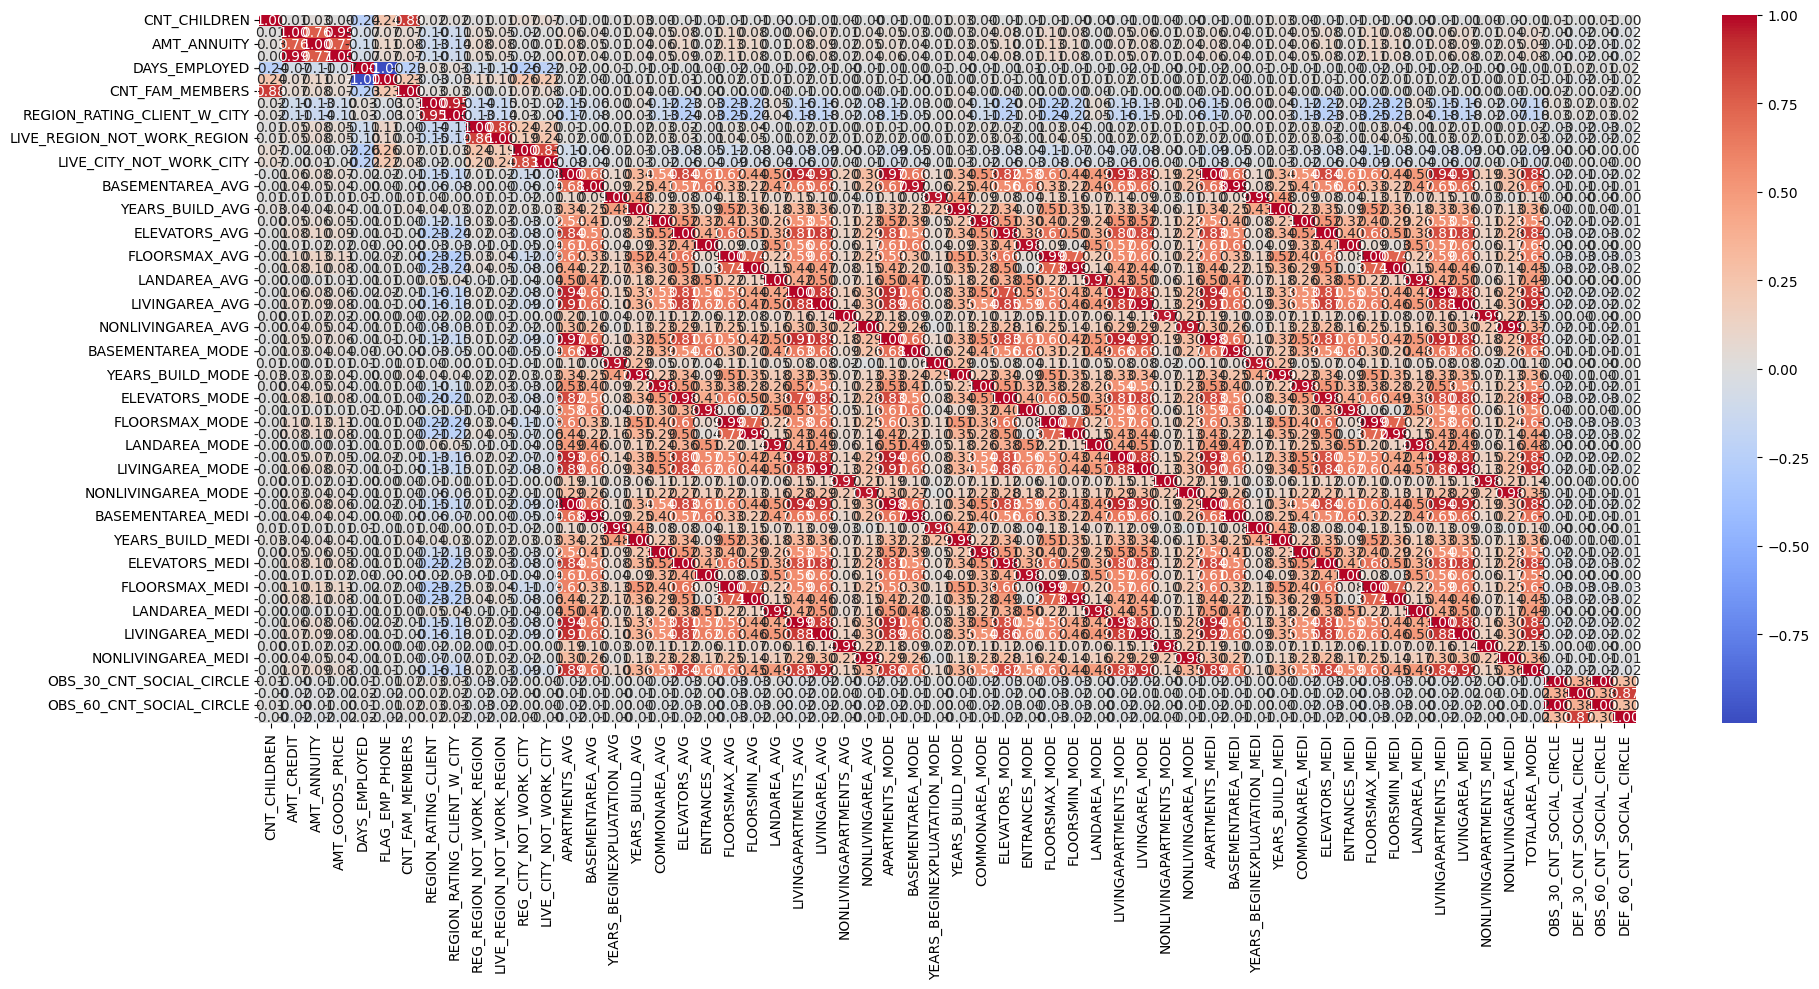

In [9]:
import seaborn as sns
plt.figure(figsize = (20,10))
threshold = 0.7
corr = df.drop(columns = ['SK_ID_CURR']).corr(numeric_only = True)
corr_no_diag = corr.mask(np.eye(len(corr), dtype = bool))
selected_cols = corr_no_diag.columns[
    corr_no_diag.abs().gt(threshold).any()
]
filtered_corr = corr.loc[selected_cols, selected_cols]
sns.heatmap(filtered_corr, annot = True, fmt = '.2f', cmap = 'coolwarm')
plt.tight_layout()
plt.show()

### Target Distribution

In [10]:
target_0 = train[train['TARGET'] == 0.0]
target_1 = train[train['TARGET'] == 1.0]

print("Target Distribution")
print(f"0 : {(len(target_0)/len(train))*100}%" )
print(f"1 : {(len(target_1)/len(train))*100}%" )

Target Distribution
0 : 91.92711805431351%
1 : 8.072881945686495%


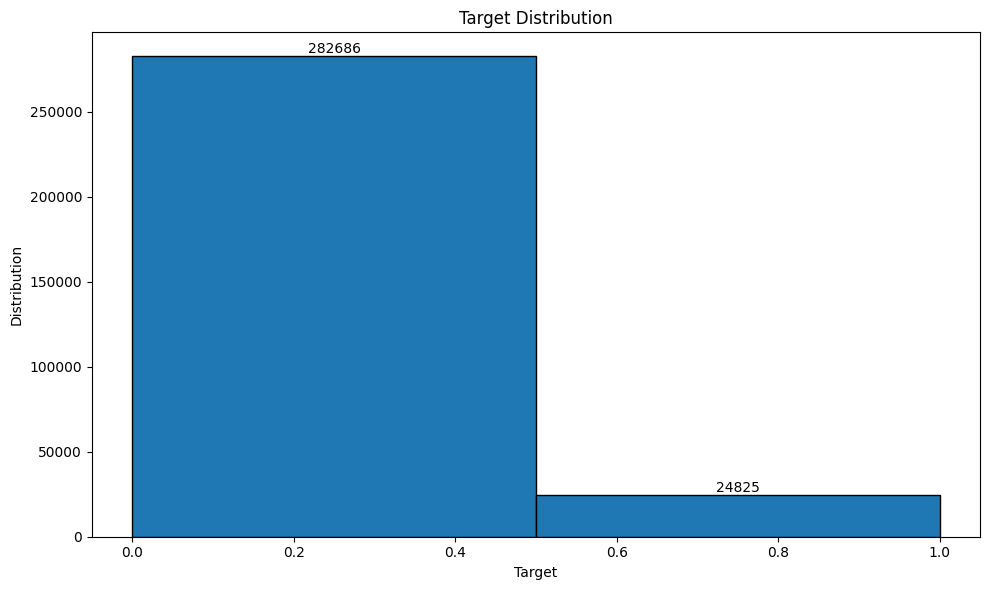

In [11]:
plt.figure(figsize = (10,6))
counts, bins, patches = plt.hist(df['TARGET'], edgecolor = 'black', bins = 2, )
plt.bar_label(patches)
plt.title("Target Distribution")
plt.xlabel("Target")
plt.ylabel("Distribution")
plt.tight_layout()
plt.show()

# 3. Feature Engineering

## 3.1 Numerical and Categorical Feature Engineering

In [12]:
# Total Document Count
doc_cols = [col for col in df.columns if col.startswith("FLAG_DOCUMENT_")]
df['APPLICATION_TOTAL_DOCUMENT'] = df[doc_cols].sum(axis = 1)
df = df.drop(columns = doc_cols)

# Days Processing + Ratios
days_col = ['DAYS_EMPLOYED', 'DAYS_BIRTH', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH']
df['APPLICATION_DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)
df['APPLICATION_DAYS_REGISTRATION'] = df['DAYS_REGISTRATION'].replace(365243, np.nan)
df['APPLICATION_DAYS_ID_PUBLISH'] = df['DAYS_ID_PUBLISH'].replace(365243, np.nan)
df['APPLICATION_DAYS_BIRTH'] = df['DAYS_BIRTH'].replace(365243, np.nan)

df['APPLICATION_DAYS_EMPLOYED_ANOM'] = (df['DAYS_EMPLOYED'] == 365243).astype(int)
df['APPLICATION_DAYS_REGISTRATION_ANOM'] = (df['DAYS_EMPLOYED'] == 365243).astype(int)
df['APPLICATION_DAYS_ID_PUBLISH_ANOM'] = (df['DAYS_EMPLOYED'] == 365243).astype(int)
df['APPLICATION_DAYS_BIRTH_ANOM'] = (df['DAYS_BIRTH'] == 365243).astype(int)
df = df.drop(columns = days_col)

df['APPLICATION_EMPLOYED_TO_BIRTH_RATIO'] = df['APPLICATION_DAYS_EMPLOYED'] / (df['APPLICATION_DAYS_BIRTH'] + 1)
df['APPLICATION_MONTHS_TO_PAY'] = df['AMT_CREDIT'] / (df['AMT_ANNUITY'] + 1)

# Income
df['APPLICATION_INCOME_TO_CREDIT'] = df['AMT_INCOME_TOTAL'] / (df['AMT_CREDIT'] + 1e-9) 
df['APPLICATION_INCOME_TO_ANNUITY'] = df['AMT_INCOME_TOTAL'] / (df["AMT_ANNUITY"] + 1e-9)
df['APPLICATION_INCOME_TO_EMPLOYED'] = df['AMT_INCOME_TOTAL'] / (df["APPLICATION_DAYS_EMPLOYED"] + 1)
df['APPLICATION_INCOME_TO_BIRTH'] = df['AMT_INCOME_TOTAL'] / (df["APPLICATION_DAYS_BIRTH"] + 1)

# Credit
df['APPLICATION_ANNUITY_TO_CREDIT'] = df['AMT_ANNUITY'] / (df['AMT_CREDIT'] + 1e-9) 
df['APPLICATION_CREDIT_TO_EMPLOYED'] = df['AMT_CREDIT'] / (df["APPLICATION_DAYS_EMPLOYED"] + 1)
df['APPLICATION_CREDIT_TO_BIRTH'] = df['AMT_CREDIT'] / (df["APPLICATION_DAYS_BIRTH"] + 1)


# Ages
df['AGE_LABEL'] = pd.cut(-df['APPLICATION_DAYS_BIRTH']/365, bins = [0,27,40,50,65,np.inf], labels = [1,2,3,4,5])

## 3.2 External Columns Engineering

In [13]:
ext_cols = ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']
if ext_cols:
    df['EXT_SOURCE_MEAN'] = df[ext_cols].mean(axis = 1)
    df['EXT_SOURCE_MIN']  = df[ext_cols].min(axis = 1)
    df['EXT_SOURCE_MAX']  = df[ext_cols].max(axis = 1)
    df['EXT_SOURCE_MEDIAN'] = df[ext_cols].median(axis = 1)
    df['EXT_SOURCE_NAN_COUNT'] = df[ext_cols].isna().sum(axis = 1)
    df['EXT_SOURCE_STD'] = df[ext_cols].std(axis = 1)
    df['EXT_1_2_RATE'] = df['EXT_SOURCE_1'] / (df['EXT_SOURCE_2']  + 1e-9)
    df['EXT_2_3_RATE'] = df['EXT_SOURCE_2'] / (df['EXT_SOURCE_3'] + 1e-9)
    df['EXT_1_3_RATE'] = df['EXT_SOURCE_1'] / (df['EXT_SOURCE_3']  + 1e-9)
    df['EXT_1_2_MUL'] = df['EXT_SOURCE_1'] * df['EXT_SOURCE_2']
    df['EXT_2_3_MUL'] = df['EXT_SOURCE_2'] * df['EXT_SOURCE_3']
    df['EXT_1_3_MUL'] = df['EXT_SOURCE_1'] * df['EXT_SOURCE_3']
    df['EXT_SOURCE_WEIGHT'] = 2*df['EXT_SOURCE_1'] + 1*df['EXT_SOURCE_2'] + 3*df['EXT_SOURCE_3']
    df['EXT_SOURCE_PROD'] = df['EXT_SOURCE_1'] * df['EXT_SOURCE_2'] * df['EXT_SOURCE_3']

# Ext vs Credit
df['EXT_1_CREDIT'] = df['EXT_SOURCE_1'] * df['AMT_CREDIT']
df['EXT_2_CREDIT'] = df['EXT_SOURCE_2'] * df['AMT_CREDIT']
df['EXT_3_CREDIT'] = df['EXT_SOURCE_3'] * df['AMT_CREDIT'] 

# Ext vs Annuity
df['EXT_1_ANNUITY'] = df['EXT_SOURCE_1'] * df['AMT_ANNUITY']
df['EXT_2_ANNUITY'] = df['EXT_SOURCE_2'] * df['AMT_ANNUITY']
df['EXT_3_ANNUITY'] = df['EXT_SOURCE_3'] * df['AMT_ANNUITY']

# Ext vs Income
df['EXT_1_INCOME'] = df['EXT_SOURCE_1'] * df['AMT_INCOME_TOTAL']
df['EXT_2_INCOME'] = df['EXT_SOURCE_2'] * df['AMT_INCOME_TOTAL']
df['EXT_3_INCOME'] = df['EXT_SOURCE_3'] * df['AMT_INCOME_TOTAL']

# Ext vs Goods
df['EXT_1_GOODS'] = df['EXT_SOURCE_1'] * df['AMT_GOODS_PRICE']
df['EXT_2_GOODS'] = df['EXT_SOURCE_2'] * df['AMT_GOODS_PRICE']
df['EXT_3_GOODS'] = df['EXT_SOURCE_3'] * df['AMT_GOODS_PRICE']

# Ext vs Days
df['EXT_1_BIRTH'] = df['EXT_SOURCE_1'] * df['APPLICATION_DAYS_BIRTH']
df['EXT_2_BIRTH'] = df['EXT_SOURCE_2'] * df['APPLICATION_DAYS_BIRTH']
df['EXT_3_BIRTH'] = df['EXT_SOURCE_3'] * df['APPLICATION_DAYS_BIRTH']

df['EXT_1_EMPLOYED'] = df['EXT_SOURCE_1'] * df['APPLICATION_DAYS_EMPLOYED']
df['EXT_2_EMPLOYED'] = df['EXT_SOURCE_2'] * df['APPLICATION_DAYS_EMPLOYED']
df['EXT_3_EMPLOYED'] = df['EXT_SOURCE_3'] * df['APPLICATION_DAYS_EMPLOYED']

df['EXT_1_ID'] = df['EXT_SOURCE_1'] * df['APPLICATION_DAYS_ID_PUBLISH']
df['EXT_2_ID'] = df['EXT_SOURCE_2'] * df['APPLICATION_DAYS_ID_PUBLISH']
df['EXT_3_ID'] = df['EXT_SOURCE_3'] * df['APPLICATION_DAYS_ID_PUBLISH']



# 4. Preprocessing

### Drop Unecessary Columns

In [14]:
df = df.drop(columns = [
    'FONDKAPREMONT_MODE',
    'HOUSETYPE_MODE',	
    'WALLSMATERIAL_MODE',
    'EMERGENCYSTATE_MODE',
    'HOUR_APPR_PROCESS_START', 
    'REG_REGION_NOT_LIVE_REGION', 
    'REG_REGION_NOT_WORK_REGION', 
    'LIVE_REGION_NOT_WORK_REGION', 
    'REG_CITY_NOT_LIVE_CITY', 
    'REG_CITY_NOT_WORK_CITY', 
    'LIVE_CITY_NOT_WORK_CITY',
    'APARTMENTS_AVG', 
    'BASEMENTAREA_AVG', 
    'YEARS_BEGINEXPLUATATION_AVG', 
    'YEARS_BUILD_AVG', 
    'COMMONAREA_AVG', 
    'ELEVATORS_AVG', 
    'ENTRANCES_AVG', 
    'FLOORSMAX_AVG', 
    'FLOORSMIN_AVG', 
    'LANDAREA_AVG', 
    'LIVINGAPARTMENTS_AVG', 
    'LIVINGAREA_AVG', 
    'NONLIVINGAPARTMENTS_AVG', 
    'NONLIVINGAREA_AVG', 
    'APARTMENTS_MODE', 
    'BASEMENTAREA_MODE', 
    'YEARS_BEGINEXPLUATATION_MODE', 
    'YEARS_BUILD_MODE', 
    'COMMONAREA_MODE', 
    'ELEVATORS_MODE', 
    'ENTRANCES_MODE', 
    'FLOORSMAX_MODE', 
    'FLOORSMIN_MODE', 
    'LANDAREA_MODE', 
    'LIVINGAPARTMENTS_MODE', 
    'LIVINGAREA_MODE', 
    'NONLIVINGAPARTMENTS_MODE', 
    'NONLIVINGAREA_MODE', 
    'APARTMENTS_MEDI', 
    'BASEMENTAREA_MEDI', 
    'YEARS_BEGINEXPLUATATION_MEDI', 
    'YEARS_BUILD_MEDI', 
    'COMMONAREA_MEDI',
    'ELEVATORS_MEDI', 
    'ENTRANCES_MEDI', 
    'FLOORSMAX_MEDI', 
    'FLOORSMIN_MEDI', 
    'LANDAREA_MEDI', 
    'LIVINGAPARTMENTS_MEDI', 
    'LIVINGAREA_MEDI', 
    'NONLIVINGAPARTMENTS_MEDI', 
    'NONLIVINGAREA_MEDI',
    'TOTALAREA_MODE',
    'OBS_30_CNT_SOCIAL_CIRCLE',
    'OBS_60_CNT_SOCIAL_CIRCLE',
    'CNT_CHILDREN',
    'FLAG_MOBIL', 
    'FLAG_EMP_PHONE', 
    'FLAG_WORK_PHONE', 
    'FLAG_CONT_MOBILE', 
    'FLAG_PHONE', 
    'FLAG_EMAIL', 
    'CNT_FAM_MEMBERS',
    'DAYS_LAST_PHONE_CHANGE'
])

df.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,...,EXT_3_GOODS,EXT_1_BIRTH,EXT_2_BIRTH,EXT_3_BIRTH,EXT_1_EMPLOYED,EXT_2_EMPLOYED,EXT_3_EMPLOYED,EXT_1_ID,EXT_2_ID,EXT_3_ID
0,100002,1.0,Cash loans,M,N,Y,202500.0,406597.5,24700.5,351000.0,...,48920.898815,-785.612748,-2487.756636,-1318.634256,-52.894548,-167.498254,-88.782372,-176.038371,-557.451017,-295.476654
1,100003,0.0,Cash loans,F,N,N,270000.0,1293502.5,35698.5,1129500.0,...,NaN,-5218.396475,-10431.950422,NaN,-369.785566,-739.227981,NaN,-90.578788,-181.073521,NaN
2,100004,0.0,Revolving loans,M,Y,Y,67500.0,135000.0,6750.0,135000.0,...,98491.503245,NaN,-10587.901540,-13895.327191,NaN,-125.080219,-164.152505,NaN,-1407.013483,-1846.533294
3,100006,0.0,Cash loans,F,N,Y,135000.0,312682.5,29686.5,297000.0,...,NaN,NaN,-12361.644326,NaN,NaN,-1976.692297,NaN,NaN,-1585.126400,NaN
4,100007,0.0,Cash loans,M,N,Y,121500.0,513000.0,21865.5,513000.0,...,NaN,NaN,-6432.819536,NaN,NaN,-980.478916,NaN,NaN,-1116.028996,NaN


# 5. Save Data

In [ ]:
save_data(df, DATA_DIR + "application_train_test_final_agg.csv")